# 05. Impurities and local density of states

Add the impurity terms written in the thesis to the same imposed-vortex model. Compute a properly normalized electron LDOS and compare scalar and magnetic potentials.

**Read this notebook from top to bottom.** Each section explains one calculation before showing its code. All functions needed to run it are visible below; no earlier notebook is required.

**Source labels.** **Thesis** identifies the stated model in Aditya Banerjee's [2023 MSc thesis](https://drive.google.com/file/d/1d9WheYwEY23cPAlLxxVOUfQDr9jLdqb9/view). **Source translation** identifies the active Mathematica calculation at commit `d88d12c`. **Extension / algebra** identifies new Python implementation or explicit derivations. Numerical output is evidence only for the displayed parameters. No speculative physical identification is assumed.

**Units and conventions.** Choose one energy unit $E_0$ and lattice spacing $a$. Displayed energies mean $E/E_0$, coordinates mean $x/a$, and $k_x,k_y$ mean momentum times $a$. Thus $m,\lambda,\mu,\Delta,V,k_BT$ all have energy units before rescaling. Eigenvectors have norm one and dimensionless components. This is a nonrelativistic lattice calculation; no spacetime metric signature is used. Boundary conditions and the spin/Nambu basis are stated where each matrix is built.

**Code provenance.** The original files are [BdG topological.nb](https://github.com/adicos0/BdG-code-for-Topological-superconductor-with-vortex-/blob/d88d12cded1a954d53c2d36d515525c8100ded1c/BdG%20topological.nb) and [added vortex.nb](https://github.com/adicos0/BdG-code-for-Topological-superconductor-with-vortex-/blob/d88d12cded1a954d53c2d36d515525c8100ded1c/added%20vortex.nb). See [SOURCE_MAP.md](../SOURCE_MAP.md) for exact cells, differences and references. Python functions are also collected in `python/bdg_models.py` for testing; the definitions here are identical.

## 1. Imports

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.special import expit
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

## 2. Add one impurity — thesis-based extension

**Thesis:** §4.3, Eqs. (4.6)–(4.7), and §4.4.1–4.4.2 distinguish
$$H_{\rm imp}^{\rm scalar}=V(n_{j\uparrow}+n_{j\downarrow}),\qquad
H_{\rm imp}^{\rm magnetic}=V(n_{j\uparrow}-n_{j\downarrow}).$$
$j$ is the impurity site, $V$ is an energy, and $n_{j\sigma}=c_{j\sigma}^\dagger c_{j\sigma}$ is an occupation operator. A scalar impurity adds $(V,V)$ to the two spin diagonals. A magnetic impurity polarized along $z$ adds $(V,-V)$.

Construct the electron matrix first, then rebuild the complete BdG matrix. This automatically puts the conjugated, sign-reversed impurity into the hole sector. Adding the same sign to both particle and hole blocks would break this convention.

**Scope:** impurity terms are disabled in the committed Mathematica loop. The Python calculations below implement the thesis equations as an extension. The pairing profile and chemical potential are held fixed at every impurity strength. Thus this is a **frozen-profile comparison**, not a self-consistent reproduction of the thesis impurity figures. Open boundaries and the canonical basis from notebook 02 are used.

In [2]:
def coordinates(nx, ny):
    """Zero-based version of the source's x-outer, y-inner site order."""
    return np.array([(x, y) for x in range(nx) for y in range(ny)])

def thesis_normal(nx, ny, m=0.5, lam=1.0, mu=0.0, periodic=False):
    """Extension from thesis Eqs. 4.8-4.9, not the active source hopping.

    Fourier convention c_r = sum_k exp(-i k.r)c_k / sqrt(N).
    Build site-major 2x2 blocks, then permute to spin-major order.
    """
    identity = np.eye(2)
    sx = np.array([[0, 1], [1, 0]], complex)
    sy = np.array([[0, -1j], [1j, 0]], complex)
    sz = np.diag([1., -1.])
    n = nx*ny
    h = np.kron(np.eye(n), 1.5*m*sz-mu*identity).astype(complex)
    for i, (x, y) in enumerate(coordinates(nx, ny)):
        for dx, dy, spin in [(1, 0, sx), (0, 1, sy)]:
            for distance, hop in [(1, -m/2*sz + 0.5j*lam*spin),
                                  (2, m/8*sz)]:
                xx, yy = x+distance*dx, y+distance*dy
                if not periodic and not (0 <= xx < nx and 0 <= yy < ny):
                    continue
                j = (xx % nx)*ny + (yy % ny)
                h[2*i:2*i+2, 2*j:2*j+2] += hop
                h[2*j:2*j+2, 2*i:2*i+2] += hop.conj().T
    order = np.r_[np.arange(0, 2*n, 2), np.arange(1, 2*n, 2)]
    return h[np.ix_(order, order)]

def canonical_bdg(electron, delta):
    """Standard spin-singlet BdG in (c_up,c_down,c_up†,c_down†)."""
    n = len(delta)
    zero = np.zeros((n, n), complex)
    pairing = np.block([[zero, np.diag(delta)], [-np.diag(delta), zero]])
    return np.block([[electron, pairing],
                     [pairing.conj().T, -electron.conj()]])

def canonical_checks(matrix):
    """Hermiticity and particle-hole residuals (max absolute entries)."""
    half = len(matrix)//2
    exchange = np.r_[np.arange(half, 2*half), np.arange(half)]
    return (np.max(abs(matrix-matrix.conj().T)),
            np.max(abs(matrix.conj()[np.ix_(exchange, exchange)]+matrix)))

def vortex_field(nx, ny, delta0=0.2, xi=1.5, center=None, winding=1):
    """Imposed open-sample extension of Eq.4.2 with quadrant-correct phase."""
    if xi <= 0:
        raise ValueError('xi must be positive.')
    if center is None:
        center = ((nx-1)/2, (ny-1)/2)
    xy = coordinates(nx, ny)-np.asarray(center)
    radius = np.hypot(xy[:, 0], xy[:, 1])
    phase = np.arctan2(xy[:, 1], xy[:, 0])
    return delta0*np.tanh(radius/xi)*np.exp(1j*winding*phase)

def add_impurity(electron, site, strength, magnetic=False):
    """Frozen-profile extension: Eq.4.6 scalar or Eq.4.7 z-magnetic impurity."""
    h = electron.copy()
    n = h.shape[0]//2
    h[site, site] += strength
    h[n+site, n+site] += -strength if magnetic else strength
    return h

def electron_ldos(energies, vectors, site, grid, eta=0.02):
    """Spin-summed electron LDOS using ALL BdG eigenstates exactly once."""
    if eta <= 0:
        raise ValueError('eta must be positive.')
    n = vectors.shape[0]//4
    weights = abs(vectors[site])**2 + abs(vectors[n+site])**2
    lorentzian = eta/np.pi/((grid[:, None]-energies[None, :])**2+eta**2)
    return lorentzian @ weights, weights.sum()

## 3. Define the electron LDOS without double counting

**Thesis:** §4.1, p. 32, introduces local density of states. **Explicit convention and algebra here:** use all $4N$ BdG states and the electron components only:
$$\rho_i(E)=\sum_{n=1}^{4N}\left(|u_{i\uparrow,n}|^2+|u_{i\downarrow,n}|^2\right)L_\eta(E-E_n),$$
$$L_\eta(x)=\frac{\eta}{\pi(x^2+\eta^2)},\qquad \eta>0.$$
$\eta$ is a numerical broadening energy. $L_\eta$ and $\rho_i$ have inverse-energy units. This spin-summed convention differs by a factor of two from a spin-averaged LDOS. Do not also add hole weights when using this complete signed spectrum.

The normalization follows in steps:
$$\int_{-\infty}^{\infty}L_\eta(x)\,dx=
\left[\frac1\pi\arctan(x/\eta)\right]_{-\infty}^{\infty}=1,$$
$$\int\rho_i(E)\,dE=\sum_n|u_{i\uparrow,n}|^2+\sum_n|u_{i\downarrow,n}|^2=1+1=2.$$
The last equality follows from completeness of the normalized eigenvectors. The finite plotting window does not contain all spectral weight; the code checks the exact weight sum instead. As $\eta\to0^+$, each Lorentzian approaches a delta distribution. A finite-width zero-energy peak does not prove an exact zero eigenvalue.

In [3]:
nx = ny = 11
n = nx*ny
center = (5, 5)
site = center[0]*ny+center[1]
delta0, xi, mu = 0.2, 1.5, -0.7
electron = thesis_normal(nx, ny, mu=mu, periodic=False)
delta = vortex_field(nx, ny, delta0, xi, center)
grid = np.linspace(-0.6, 0.6, 601)
eta = 0.02
strengths = [0.0, 0.5, 2.0]  # tutorial sweep in E0; not fitted thesis results
results = {}
for magnetic in [False, True]:
    label = "Magnetic (z)" if magnetic else "Scalar"
    for strength in strengths:
        changed = add_impurity(electron, site, strength, magnetic)
        h = canonical_bdg(changed, delta)
        assert max(canonical_checks(h)) < 1e-12
        energies, vectors = eigh(h)
        rho, weight = electron_ldos(energies, vectors, site, grid, eta)
        assert np.isclose(weight, 2)
        results[label, strength] = (energies, rho)
        print(f"{label:12s} V/E0={strength:3.1f}: min |E|/E0={min(abs(energies)):.6f}; total electron weight={weight:.6f}")

Scalar       V/E0=0.0: min |E|/E0=0.000613; total electron weight=2.000000
Scalar       V/E0=0.5: min |E|/E0=0.002635; total electron weight=2.000000


Scalar       V/E0=2.0: min |E|/E0=0.009491; total electron weight=2.000000


Magnetic (z) V/E0=0.0: min |E|/E0=0.000613; total electron weight=2.000000


Magnetic (z) V/E0=0.5: min |E|/E0=0.002635; total electron weight=2.000000
Magnetic (z) V/E0=2.0: min |E|/E0=0.009491; total electron weight=2.000000


## 4. Compare spectra and core LDOS

The impurity sits at the imposed vortex centre. All panels use the same energy window and broadening, making the curves comparable. The zero-potential results must agree because the scalar and magnetic perturbations both vanish at $V=0$.

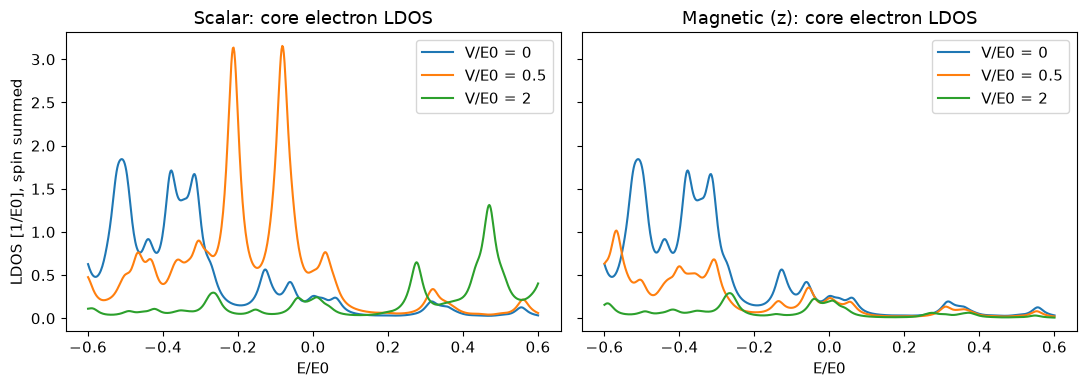

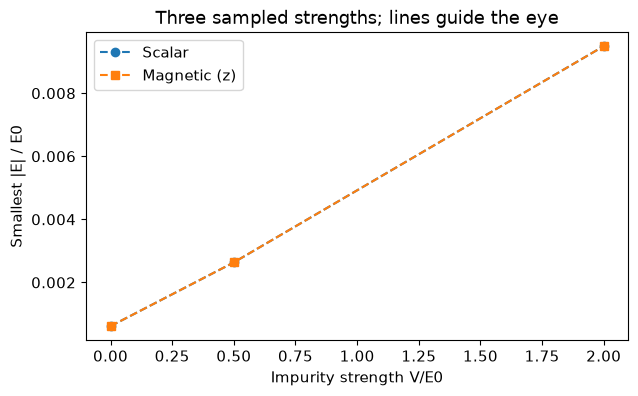

In [4]:
assert np.allclose(results["Scalar", 0.0][0], results["Magnetic (z)", 0.0][0])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, label in zip(axes, ["Scalar", "Magnetic (z)"]):
    for strength in strengths:
        ax.plot(grid, results[label, strength][1], label=f"V/E0 = {strength:g}")
    ax.set(xlabel="E/E0", title=f"{label}: core electron LDOS")
    ax.legend()
axes[0].set_ylabel("LDOS [1/E0], spin summed")
fig.tight_layout()
plt.show()
fig, ax = plt.subplots()
for label, marker in [("Scalar", "o"), ("Magnetic (z)", "s")]:
    ax.plot(strengths, [min(abs(results[label, v][0])) for v in strengths], marker+"--", label=label)
ax.set(xlabel="Impurity strength V/E0", ylabel="Smallest |E| / E0", title="Three sampled strengths; lines guide the eye")
ax.legend()
plt.show()

## 5. What can be concluded

**Computed facts:** the tables and curves show the response of this specified finite, open, fixed-profile model. The smallest-absolute-energy curves overlap to the displayed precision for this particular sweep, while the LDOS curves differ. Equality of one spectral statistic does not make the two perturbations equivalent. **Model assumptions:** onsite scalar or z-polarized magnetic perturbation; no Hartree correction; fixed chemical potential, gap amplitude and vortex phase; phenomenological Lorentzian broadening.

**Interpretation not established:** neither a zero-bias LDOS feature nor weak movement of a finite-size eigenvalue is sufficient to identify a protected Majorana mode. Such an identification requires additional spatial, particle–hole, finite-size and topology checks. This notebook does not claim that the tutorial sweep reproduces the thesis figures or experimentally validates the model.

For sources and the precise distinction between original code, algebraic conventions and extensions, return to [SOURCE_MAP.md](../SOURCE_MAP.md).